# Avaliação e Interpretabilidade — FD001

**Fase:** 04 — Avaliação Final & Interpretabilidade  
**Subset:** FD001 (1 condição operacional, 1 modo de falha)

**Agenda:**
1. Resumo Executivo
2. Comparação final de modelos (RMSE, MAE, PHM Score)
3. Análise de erro no conjunto de teste
4. Erro por faixa de RUL — onde o modelo erra mais?
5. Custo assimétrico — previsões tardias vs adiantadas
6. Análise de motores difíceis — casos onde o modelo sistematicamente falha
7. Interpretabilidade SHAP — quais sensores mais influenciam?
8. SHAP Waterfall — como o modelo avalia motores individuais e o que fazer com isso
9. SHAP Dependence — como cada sensor afeta a previsão
10. Limitações do estudo
11. Síntese para o artigo

## Setup

In [19]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import shap
from sklearn.metrics import r2_score

from src.evaluation.metrics import rmse, mae, phm_score
from src.utils.config import MODELS_DIR, PROCESSED_DIR

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120

SUBSET = "FD001"
MODELOS_ORDEM = ["Ridge", "Random Forest", "XGBoost", "LightGBM", "Stacking"]
CORES = sns.color_palette("muted", len(MODELOS_ORDEM))
HORAS_POR_CICLO = 10

print(f"Raiz do projeto: {PROJECT_ROOT}")
print("Imports OK")

Raiz do projeto: c:\Users\Pichau\Documents\cmapss-rul-prediction
Imports OK


In [20]:
# Dados processados
train_df = pd.read_parquet(PROCESSED_DIR / f"train_{SUBSET}.parquet", engine="pyarrow")
test_df  = pd.read_parquet(PROCESSED_DIR / f"test_{SUBSET}.parquet",  engine="pyarrow")

FEATURE_COLS = [c for c in train_df.columns if c not in ("unit_id", "cycle", "rul")]
X_train  = train_df[FEATURE_COLS].values
y_train  = train_df["rul"].values.astype(float)
X_test   = test_df[FEATURE_COLS].values
y_test   = test_df["rul"].values.astype(float)
X_test_df = pd.DataFrame(X_test, columns=FEATURE_COLS)

# Modelos treinados
print("Carregando modelos...", end=" ")
modelos = {
    "Ridge":         joblib.load(MODELS_DIR / f"ridge_{SUBSET}.pkl"),
    "Random Forest": joblib.load(MODELS_DIR / f"random_forest_{SUBSET}.pkl"),
    "XGBoost":       joblib.load(MODELS_DIR / f"xgboost_{SUBSET}.pkl"),
    "LightGBM":      joblib.load(MODELS_DIR / f"lightgbm_{SUBSET}.pkl"),
    "Stacking":      joblib.load(MODELS_DIR / f"stacking_{SUBSET}.pkl"),
}
print("OK")

previsoes = {nome: m.predict(X_test) for nome, m in modelos.items()}

df_resultados = pd.read_csv(MODELS_DIR / f"resultados_{SUBSET}.csv")
df_resultados["modelo"] = pd.Categorical(
    df_resultados["modelo"], categories=MODELOS_ORDEM, ordered=True
)
df_resultados = df_resultados.sort_values("modelo").reset_index(drop=True)

print(f"\nTreino: {train_df.shape} | Teste: {test_df.shape} | Features: {len(FEATURE_COLS)}")
print(f"RUL teste — min: {y_test.min():.0f}, max: {y_test.max():.0f}, media: {y_test.mean():.1f}")

Carregando modelos... OK

Treino: (20631, 87) | Teste: (100, 87) | Features: 84
RUL teste — min: 7, max: 145, media: 75.5


---
## 1. Resumo Executivo

Este notebook apresenta os resultados finais do projeto de forma que seja diretamente utilizável no artigo de MBA. O resumo abaixo deve ser lido antes dos detalhes — estrutura de *executive report*: conclusão primeiro, evidências depois.

In [21]:
# Calcula SHAP antecipadamente para o resumo executivo
print("Calculando SHAP values (XGBoost)...", end=" ")
explainer = shap.TreeExplainer(modelos["XGBoost"])
shap_values = explainer.shap_values(X_test_df)
print("OK")

# Importância por sensor
df_shap_feat = pd.DataFrame({
    "feature":       FEATURE_COLS,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0),
})
df_shap_feat["sensor"] = df_shap_feat["feature"].str.extract(r"(sensor_\d+)")
importancia_sensor = (
    df_shap_feat.groupby("sensor")["mean_abs_shap"]
    .sum().sort_values(ascending=False)
)
top3_sensores = importancia_sensor.head(3).index.tolist()

xgb_row   = df_resultados[df_resultados.modelo == "XGBoost"].iloc[0]
ridge_row  = df_resultados[df_resultados.modelo == "Ridge"].iloc[0]

ganho_rmse = ridge_row["test_rmse"] - xgb_row["test_rmse"]
y_pred_xgb = previsoes["XGBoost"]
pct_atrasados_xgb = (y_pred_xgb > y_test).mean() * 100

print()
print("=" * 65)
print("RESUMO EXECUTIVO — FD001 (100 motores de teste)")
print("=" * 65)

print("\nPERGUNTA: Dado o historico de sensores de um motor turbofan,")
print("          quantos ciclos restam ate a falha?")

print("\nMODELO RECOMENDADO: XGBoost")
print(f"  RMSE:      {xgb_row['test_rmse']:.1f} ciclos  "
      f"= {xgb_row['test_rmse'] * HORAS_POR_CICLO:.0f}h de incerteza  "
      f"[benchmark < 15 ciclos: {'APROVADO' if xgb_row['test_rmse'] < 15 else 'REPROVADO'}]")
print(f"  MAE:       {xgb_row['test_mae']:.1f} ciclos  = {xgb_row['test_mae'] * HORAS_POR_CICLO:.0f}h de erro medio")
print(f"  PHM Score: {xgb_row['test_phm']:.0f}  (Ridge baseline: {ridge_row['test_phm']:.0f})")
print(f"  Atrasados: {pct_atrasados_xgb:.0f}% dos motores (pred > real — risco operacional)")

print(f"\nGANHO SOBRE O BASELINE LINEAR (Ridge):")
print(f"  -{ganho_rmse:.1f} ciclos RMSE = -{ganho_rmse * HORAS_POR_CICLO:.0f}h de incerteza por evento")
print(f"  = {ganho_rmse / ridge_row['test_rmse'] * 100:.0f}% de reducao no erro quadratico medio")

print(f"\nSENSORES MAIS RELEVANTES (SHAP — XGBoost):")
for i, s in enumerate(top3_sensores, 1):
    print(f"  {i}. {s}  (importancia SHAP: {importancia_sensor[s]:.3f})")

print("\nCONCLUSAO OPERACIONAL:")
print(f"  O XGBoost prediz o RUL com erro medio de {xgb_row['test_mae']:.0f} ciclos (~{xgb_row['test_mae']*HORAS_POR_CICLO:.0f}h).")
print(f"  Em {100-pct_atrasados_xgb:.0f}% dos casos, a previsao e conservadora (adiantada)")
print(f"  — o motor tem mais vida do que previsto, gerando manutencao precoce")
print(f"  mas evitando falhas em operacao.")

Calculando SHAP values (XGBoost)... OK

RESUMO EXECUTIVO — FD001 (100 motores de teste)

PERGUNTA: Dado o historico de sensores de um motor turbofan,
          quantos ciclos restam ate a falha?

MODELO RECOMENDADO: XGBoost
  RMSE:      12.5 ciclos  = 125h de incerteza  [benchmark < 15 ciclos: APROVADO]
  MAE:       9.0 ciclos  = 90h de erro medio
  PHM Score: 206  (Ridge baseline: 501)
  Atrasados: 63% dos motores (pred > real — risco operacional)

GANHO SOBRE O BASELINE LINEAR (Ridge):
  -6.1 ciclos RMSE = -61h de incerteza por evento
  = 33% de reducao no erro quadratico medio

SENSORES MAIS RELEVANTES (SHAP — XGBoost):
  1. sensor_11  (importancia SHAP: 12.811)
  2. sensor_4  (importancia SHAP: 6.846)
  3. sensor_12  (importancia SHAP: 5.961)

CONCLUSAO OPERACIONAL:
  O XGBoost prediz o RUL com erro medio de 9 ciclos (~90h).
  Em 37% dos casos, a previsao e conservadora (adiantada)
  — o motor tem mais vida do que previsto, gerando manutencao precoce
  mas evitando falhas em operac

---
## 2. Comparação Final de Modelos

Todos os modelos foram treinados no protocolo idêntico:
- **Split:** GroupKFold(5) por `unit_id` — sem vazamento entre folds
- **Tuning:** Optuna TPE, 100 trials, minimizando CV RMSE
- **Avaliação final:** modelo treinado em X completo, avaliado uma única vez no teste

As três métricas são complementares:
- **RMSE** — penaliza erros grandes; métrica padrão da área PHM
- **MAE** — leitura direta em ciclos; mais intuitivo para audiência de negócio
- **PHM Score (Saxena 2008)** — captura a assimetria real do custo (errar tarde é exponencialmente pior)

In [22]:
RMSE_BENCHMARK = 15.0

linhas = []
for _, row in df_resultados.iterrows():
    aprovado = "OK" if row["test_rmse"] < RMSE_BENCHMARK else "—"
    linhas.append({
        "Modelo":        row["modelo"],
        "CV RMSE":       f"{row['cv_rmse']:.2f} \u00b1 {row['cv_rmse_std']:.2f}",
        "CV MAE":        f"{row['cv_mae']:.2f} \u00b1 {row['cv_mae_std']:.2f}",
        "Teste RMSE":    round(row["test_rmse"], 2),
        "Teste MAE":     round(row["test_mae"],  2),
        "Teste PHM":     round(row["test_phm"],  1),
        f"<15 ciclos?": aprovado,
    })

df_display = pd.DataFrame(linhas).set_index("Modelo")

def highlight_min(s):
    is_min = s == s.min()
    return ["background-color: #d4edda; font-weight: bold" if v else "" for v in is_min]

df_display.style.apply(highlight_min, subset=["Teste RMSE", "Teste MAE", "Teste PHM"])

,CV RMSE,CV MAE,Teste RMSE,Teste MAE,Teste PHM,<15 ciclos?
Modelo,,,,,,
Ridge,16.81 ± 0.51,13.73 ± 0.69,18.590000,14.850000,501.200000,—
Random Forest,12.67 ± 1.02,9.11 ± 0.81,13.420000,10.020000,252.600000,OK
XGBoost,12.27 ± 0.67,8.70 ± 0.58,12.500000,9.040000,206.300000,OK
LightGBM,12.40 ± 0.78,8.73 ± 0.65,12.790000,9.270000,222.400000,OK
Stacking,12.23 ± 0.70,8.55 ± 0.62,12.740000,9.180000,220.500000,OK


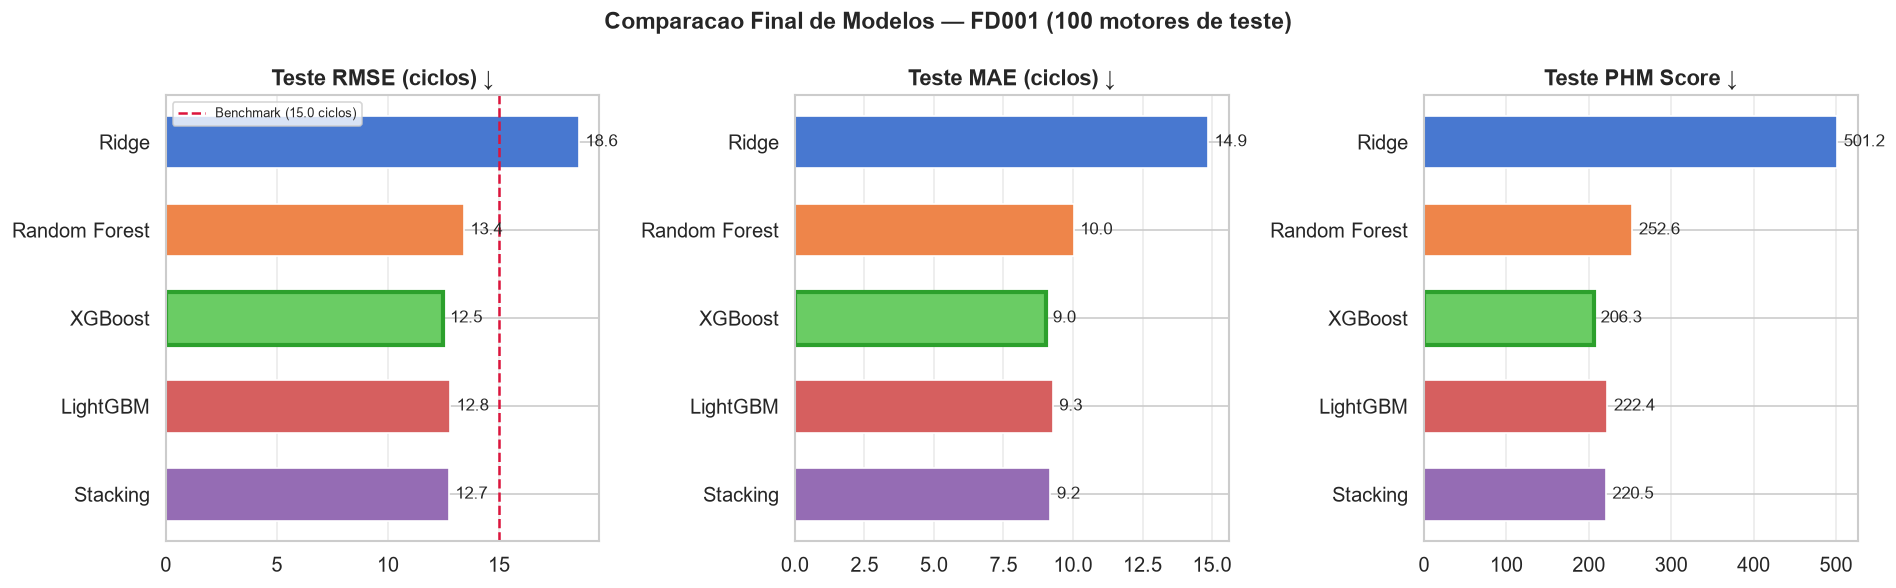

Reducao Ridge -> XGBoost: -6.10 ciclos (33%)
Modelos que passam no benchmark de 15 ciclos: Random Forest, XGBoost, LightGBM, Stacking


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metricas_plot = [
    ("test_rmse", "Teste RMSE (ciclos) \u2193"),
    ("test_mae",  "Teste MAE (ciclos) \u2193"),
    ("test_phm",  "Teste PHM Score \u2193"),
]

for ax, (col, titulo) in zip(axes, metricas_plot):
    valores = df_resultados[col].values
    bars = ax.barh(MODELOS_ORDEM, valores, color=CORES, edgecolor="white", height=0.6)
    ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=10)
    idx_min = int(np.argmin(valores))
    bars[idx_min].set_edgecolor("#2ca02c")
    bars[idx_min].set_linewidth(2.5)
    if col == "test_rmse":
        ax.axvline(RMSE_BENCHMARK, color="crimson", lw=1.5, linestyle="--",
                   label=f"Benchmark ({RMSE_BENCHMARK} ciclos)")
        ax.legend(fontsize=8)
    ax.set_title(titulo, fontweight="bold")
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.4)

fig.suptitle("Comparacao Final de Modelos — FD001 (100 motores de teste)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

rmse_ridge_v = df_resultados.loc[df_resultados.modelo == "Ridge",   "test_rmse"].values[0]
rmse_xgb_v   = df_resultados.loc[df_resultados.modelo == "XGBoost", "test_rmse"].values[0]
print(f"Reducao Ridge -> XGBoost: -{rmse_ridge_v - rmse_xgb_v:.2f} ciclos "
      f"({(1 - rmse_xgb_v / rmse_ridge_v) * 100:.0f}%)")
print(f"Modelos que passam no benchmark de 15 ciclos: "
      f"{', '.join(df_resultados.loc[df_resultados.test_rmse < RMSE_BENCHMARK, 'modelo'].tolist())}")

---
## 3. Análise de Erro no Conjunto de Teste

O scatter plot posiciona cada motor em (`RUL real`, `RUL predito`). A diagonal y = x é o preditor perfeito. Pontos **acima da diagonal** são previsões **tardias** (predito > real) — o cenário de maior risco: o motor pode falhar antes da manutenção planejada. Pontos **abaixo** são previsões **adiantadas** — causam manutenção prematura, mas o motor está seguro.

A **banda cinza** representa ±20 ciclos (±200h) de tolerância — limiar operacional aceitável para planejamento logístico.

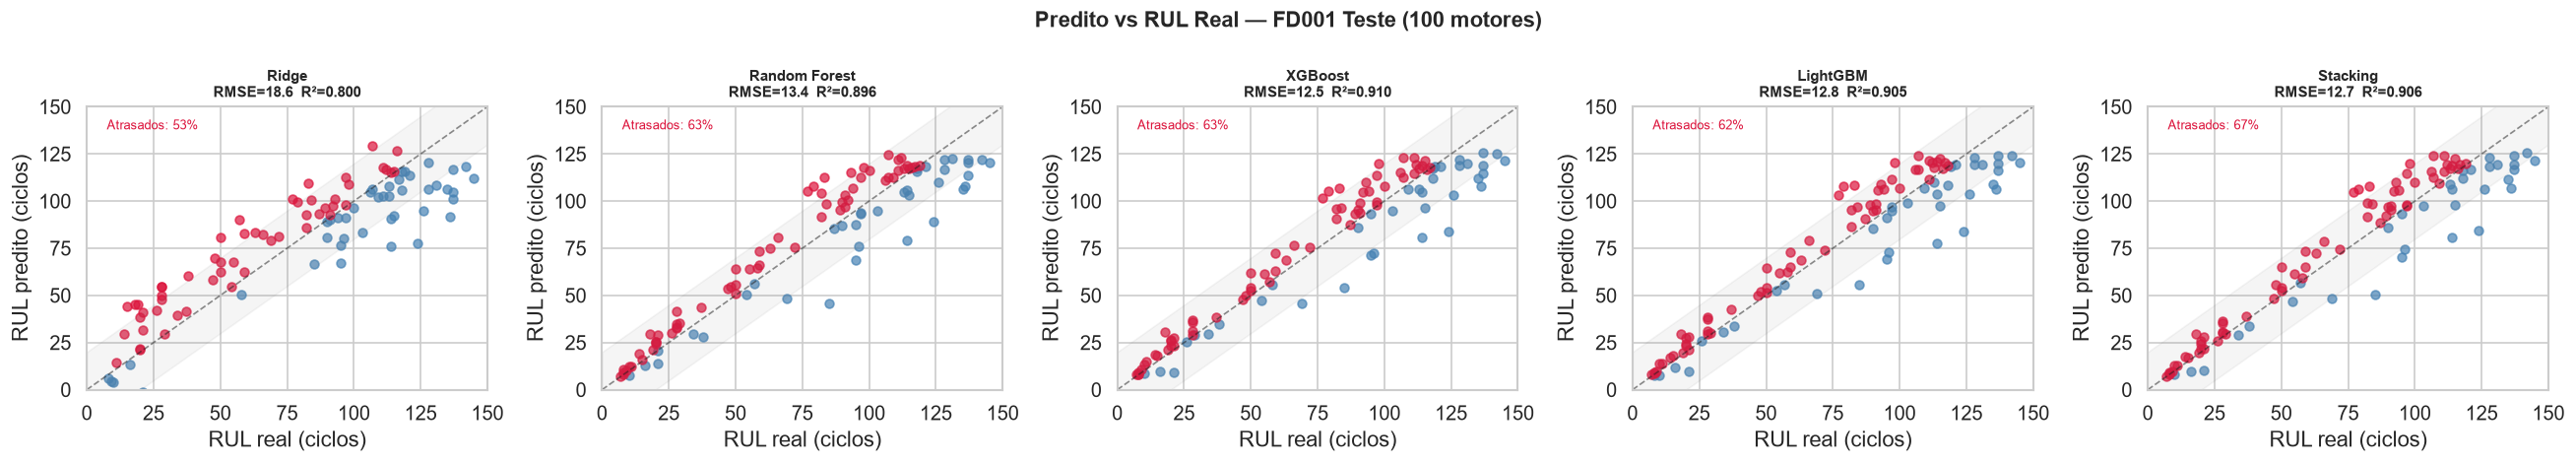

In [24]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
v_max = max(y_test.max(), max(p.max() for p in previsoes.values())) + 5
lim = (0, v_max)

for ax, nome in zip(axes, MODELOS_ORDEM):
    y_pred = previsoes[nome]
    atrasado = y_pred > y_test
    r2 = r2_score(y_test, y_pred)

    ax.scatter(y_test[~atrasado], y_pred[~atrasado],
               color="steelblue", alpha=0.7, s=28, label="Adiantado")
    ax.scatter(y_test[atrasado],  y_pred[atrasado],
               color="crimson",   alpha=0.7, s=28, label="Atrasado")
    ax.plot(lim, lim, "k--", lw=1, alpha=0.5)
    x_band = np.linspace(0, v_max, 100)
    ax.fill_between(x_band, x_band - 20, x_band + 20,
                    color="gray", alpha=0.08, label="\u00b120 ciclos")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("RUL real (ciclos)"); ax.set_ylabel("RUL predito (ciclos)")
    ax.set_title(f"{nome}\nRMSE={rmse(y_test, y_pred):.1f}  R\u00b2={r2:.3f}",
                 fontsize=9, fontweight="bold")
    ax.text(0.05, 0.92, f"Atrasados: {atrasado.mean()*100:.0f}%",
            transform=ax.transAxes, fontsize=8, color="crimson")

fig.suptitle("Predito vs RUL Real — FD001 Teste (100 motores)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

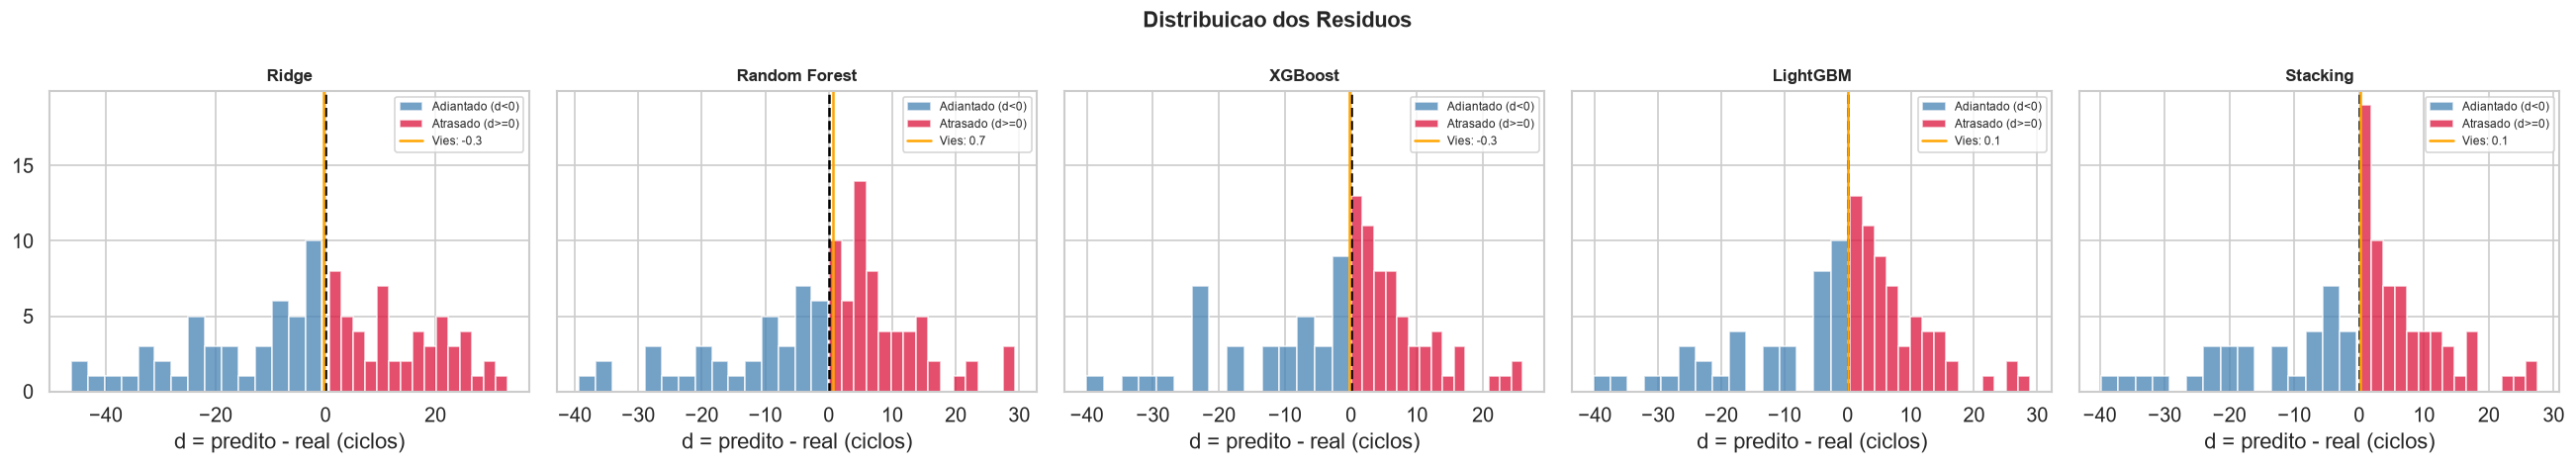

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)

for ax, nome in zip(axes, MODELOS_ORDEM):
    res = previsoes[nome] - y_test
    ax.hist(res[res < 0],  bins=15, color="steelblue", alpha=0.75, label="Adiantado (d<0)")
    ax.hist(res[res >= 0], bins=15, color="crimson",   alpha=0.75, label="Atrasado (d>=0)")
    ax.axvline(0,          color="black",  lw=1.5, linestyle="--")
    ax.axvline(res.mean(), color="orange", lw=1.5, linestyle="-",
               label=f"Vies: {res.mean():.1f}")
    ax.set_xlabel("d = predito - real (ciclos)")
    ax.set_title(nome, fontsize=10, fontweight="bold")
    ax.legend(fontsize=7)

fig.suptitle("Distribuicao dos Residuos", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 4. Erro por Faixa de RUL

A previsão de RUL não é igualmente difícil em todas as fases da vida do motor. A hipótese é que todos os modelos errem mais quando o RUL verdadeiro é **alto** (fase inicial, onde o sinal de degradação ainda é fraco e o cap de 125 ciclos comprime a variabilidade do target) e errem menos quando o motor está **próximo da falha** (sinal mais claro e urgente).

Confirmar essa hipótese é importante para o artigo: explica por que o piecewise RUL cap é necessário e onde o modelo tem menor confiabilidade.

In [26]:
bins   = [0, 30, 60, 90, 120, 200]
labels_f = ["0-30", "31-60", "61-90", "91-120", ">120"]
faixas = pd.cut(y_test, bins=bins, labels=labels_f, right=True)

mae_faixa = {}
for nome in MODELOS_ORDEM:
    erros = np.abs(previsoes[nome] - y_test)
    mae_faixa[nome] = [
        round(erros[faixas == f].mean(), 2) if (faixas == f).any() else float("nan")
        for f in labels_f
    ]

df_faixa = pd.DataFrame(mae_faixa, index=labels_f)
df_faixa.index.name = "Faixa RUL"

print("Contagem de motores por faixa de RUL verdadeiro:")
print(faixas.value_counts().sort_index().to_string())
print("\nMAE medio por faixa (ciclos):")
df_faixa

Contagem de motores por faixa de RUL verdadeiro:
0-30      25
31-60     14
61-90     15
91-120    33
>120      13

MAE medio por faixa (ciclos):


,Ridge,Random Forest,XGBoost,LightGBM,Stacking
Faixa RUL,,,,,
0-30,15.96,4.20,3.98,3.82,3.41
31-60,14.85,6.97,4.53,5.30,5.48
61-90,13.36,16.25,13.15,13.38,14.45
91-120,9.78,9.69,9.35,9.66,9.27
>120,27.29,18.19,18.08,18.25,17.92


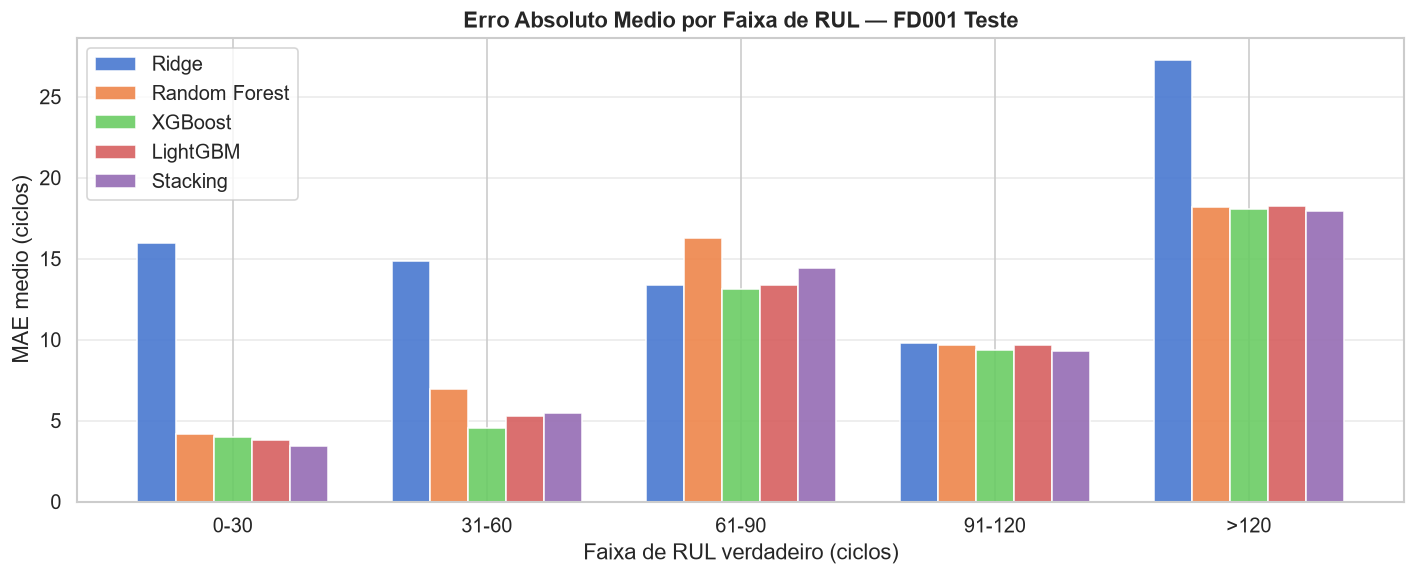

Hipotese: MAE cresce com a faixa de RUL (motor mais saudavel = mais dificil de prever)?
  XGBoost: CONFIRMADA (faixa >120 MAE=18.1 vs 0-30 MAE=4.0)
  LightGBM: CONFIRMADA (faixa >120 MAE=18.2 vs 0-30 MAE=3.8)


In [27]:
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(labels_f))
n = len(MODELOS_ORDEM)
width = 0.15

for i, (nome, cor) in enumerate(zip(MODELOS_ORDEM, CORES)):
    offset = (i - n / 2 + 0.5) * width
    vals = df_faixa[nome].values
    ax.bar(x + offset, vals, width, label=nome, color=cor, edgecolor="white", alpha=0.9)

ax.set_xticks(x)
ax.set_xticklabels(labels_f)
ax.set_xlabel("Faixa de RUL verdadeiro (ciclos)")
ax.set_ylabel("MAE medio (ciclos)")
ax.set_title("Erro Absoluto Medio por Faixa de RUL — FD001 Teste", fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

# Verifica hipótese: erro cresce com RUL?
print("Hipotese: MAE cresce com a faixa de RUL (motor mais saudavel = mais dificil de prever)?")
for nome in ["XGBoost", "LightGBM"]:
    vals = df_faixa[nome].dropna().values
    tendencia = "CONFIRMADA" if vals[-1] > vals[0] else "NAO CONFIRMADA"
    print(f"  {nome}: {tendencia} "
          f"(faixa >120 MAE={df_faixa[nome].iloc[-1]:.1f} vs 0-30 MAE={df_faixa[nome].iloc[0]:.1f})")

---
## 5. Custo Assimétrico de Erro

Errar o RUL para **mais** (prever que o motor tem mais vida do que realmente tem) é o erro perigoso — pode resultar em falha em operação. Errar para **menos** causa manutenção prematura, mas o motor está seguro.

O PHM Score (Saxena 2008) penaliza esse cenário exponencialmente. A função assimétrica significa que um único motor com previsão atrasada de +30 ciclos contribui mais ao score do que 10 motores com erro de +5 ciclos — isso reflete o custo real de uma falha catastrófica vs. múltiplas manutenções desnecessárias.

In [28]:
dados_assim = []
for nome in MODELOS_ORDEM:
    y_pred = previsoes[nome]
    d = y_pred - y_test
    atrasado  = d >= 0
    adiantado = ~atrasado
    dados_assim.append({
        "Modelo":          nome,
        "% Adiantados":    f"{adiantado.mean()*100:.0f}%",
        "MAE Adiantados":  f"{np.abs(d[adiantado]).mean():.1f}" if adiantado.any() else "—",
        "% Atrasados":     f"{atrasado.mean()*100:.0f}%",
        "MAE Atrasados":   f"{np.abs(d[atrasado]).mean():.1f}"  if atrasado.any()  else "—",
        "Vies medio (d)": f"{d.mean():.1f}",
        "PHM Score":       f"{phm_score(y_test, y_pred):.1f}",
    })

df_assim = pd.DataFrame(dados_assim).set_index("Modelo")
print("Analise de custo assimetrico — FD001 Teste (100 motores):")
df_assim

Analise de custo assimetrico — FD001 Teste (100 motores):


,% Adiantados,MAE Adiantados,% Atrasados,MAE Atrasados,Vies medio (d),PHM Score
Modelo,,,,,,
Ridge,47%,16.2,53%,13.7,-0.3,501.2
Random Forest,37%,12.6,63%,8.5,0.7,252.6
XGBoost,37%,12.6,63%,7.0,-0.3,206.3
LightGBM,38%,12.0,62%,7.6,0.1,222.4
Stacking,33%,13.7,67%,7.0,0.1,220.5


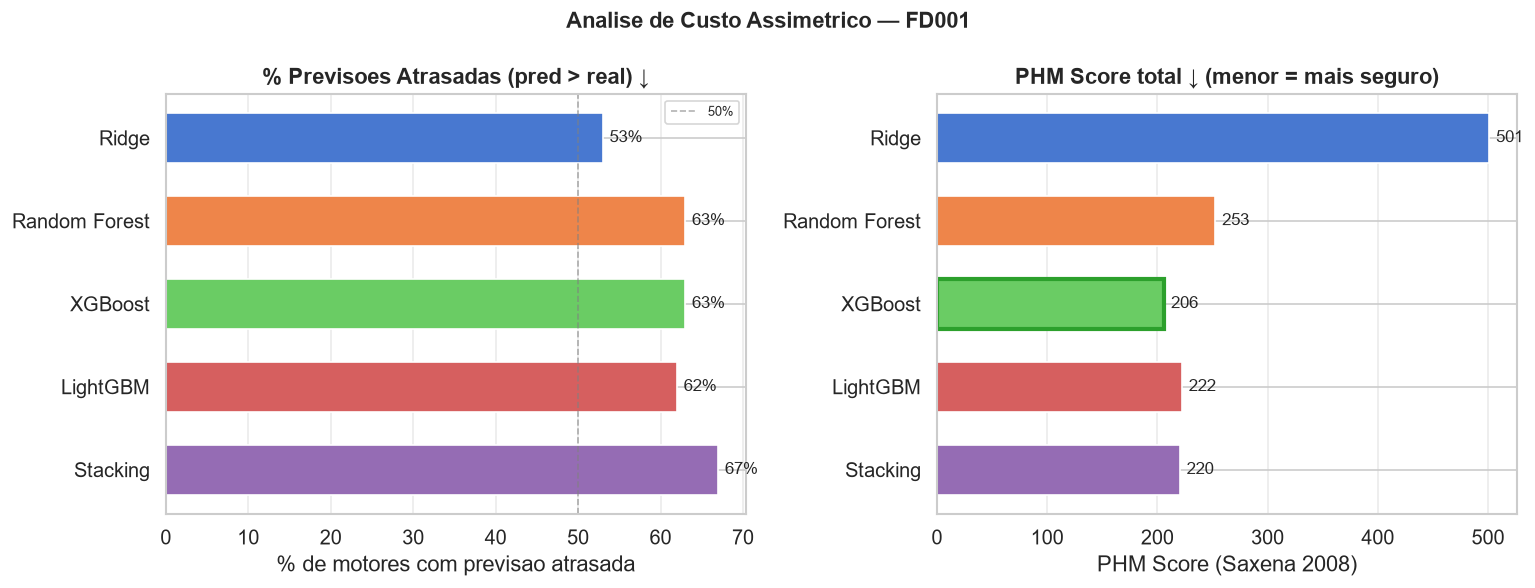

Interpretacao do PHM Score:
  Ridge:   501 pontos — baseline
  XGBoost: 206 pontos — reducao de 295 pontos
  A reducao nao e linear: a funcao exp penaliza atrasos grandes desproporcionalmente.
  Ex: 1 motor com erro +30 ciclos contribui mais ao score do que 10 motores com erro +5.


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

pct_atrasados = [(previsoes[n] > y_test).mean() * 100 for n in MODELOS_ORDEM]
bars = axes[0].barh(MODELOS_ORDEM, pct_atrasados, color=CORES, edgecolor="white", height=0.6)
axes[0].bar_label(bars, fmt="%.0f%%", padding=4, fontsize=10)
axes[0].set_xlabel("% de motores com previsao atrasada")
axes[0].set_title("% Previsoes Atrasadas (pred > real) \u2193", fontweight="bold")
axes[0].axvline(50, color="gray", linestyle="--", lw=1, alpha=0.6, label="50%")
axes[0].legend(fontsize=8)
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.4)

phm_vals = [phm_score(y_test, previsoes[n]) for n in MODELOS_ORDEM]
bars2 = axes[1].barh(MODELOS_ORDEM, phm_vals, color=CORES, edgecolor="white", height=0.6)
axes[1].bar_label(bars2, fmt="%.0f", padding=4, fontsize=10)
idx_min = int(np.argmin(phm_vals))
bars2[idx_min].set_edgecolor("#2ca02c")
bars2[idx_min].set_linewidth(2.5)
axes[1].set_xlabel("PHM Score (Saxena 2008)")
axes[1].set_title("PHM Score total \u2193 (menor = mais seguro)", fontweight="bold")
axes[1].invert_yaxis()
axes[1].grid(axis="x", alpha=0.4)

fig.suptitle("Analise de Custo Assimetrico — FD001", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Interpretacao do PHM Score:")
print(f"  Ridge:   {phm_vals[0]:.0f} pontos — baseline")
print(f"  XGBoost: {phm_vals[2]:.0f} pontos — reducao de {phm_vals[0]-phm_vals[2]:.0f} pontos")
print(f"  A reducao nao e linear: a funcao exp penaliza atrasos grandes desproporcionalmente.")
print(f"  Ex: 1 motor com erro +30 ciclos contribui mais ao score do que 10 motores com erro +5.")

---
## 6. Análise de Motores Difíceis

Mesmo o melhor modelo erra muito em alguns motores. Identificar esses casos é importante por duas razões:
1. **Para o artigo:** revela limitações sistemáticas do modelo (ex: motores com vida útil incomum)
2. **Para o negócio:** esses motores precisam de monitoramento adicional em produção

Definimos como "difícil" qualquer motor onde o XGBoost erra mais de **30 ciclos** (300h de voo).

In [30]:
LIMIAR_DIFICIL = 30

y_pred_xgb = previsoes["XGBoost"]
erros_xgb  = y_pred_xgb - y_test
casos_dificeis = np.abs(erros_xgb) > LIMIAR_DIFICIL

df_dificeis = pd.DataFrame({
    "unit_id":      test_df["unit_id"].values,
    "RUL real":     y_test,
    "RUL XGBoost":  y_pred_xgb.round(1),
    "RUL RF":       previsoes["Random Forest"].round(1),
    "RUL LGB":      previsoes["LightGBM"].round(1),
    "Erro XGB (d)": erros_xgb.round(1),
    "Tipo":         np.where(erros_xgb > 0, "Atrasado", "Adiantado"),
})[casos_dificeis].sort_values("Erro XGB (d)", key=abs, ascending=False)

print(f"Motores com |erro XGBoost| > {LIMIAR_DIFICIL} ciclos: {casos_dificeis.sum()} de 100")
print(f"  - Atrasados (risco alto): {((erros_xgb > LIMIAR_DIFICIL)).sum()}")
print(f"  - Adiantados (mant. precoce): {((erros_xgb < -LIMIAR_DIFICIL)).sum()}")
print()
print(df_dificeis.to_string(index=False))

Motores com |erro XGBoost| > 30 ciclos: 3 de 100
  - Atrasados (risco alto): 0
  - Adiantados (mant. precoce): 3

 unit_id  RUL real  RUL XGBoost  RUL RF  RUL LGB  Erro XGB (d)      Tipo
      12     124.0    83.900002    89.2     83.8         -40.1 Adiantado
      45     114.0    80.699997    79.3     77.5         -33.3 Adiantado
      93      85.0    54.200001    45.6     55.6         -30.8 Adiantado


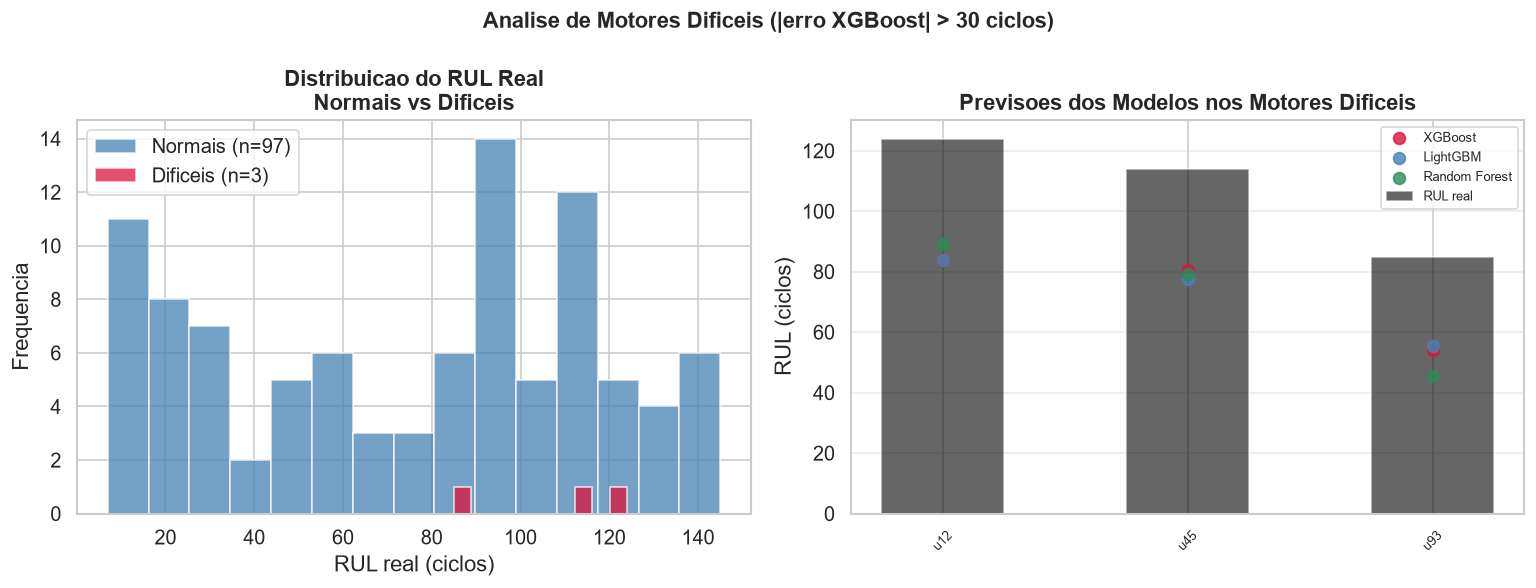


Interpretacao:
  Se os motores dificeis se concentram em faixas extremas de RUL (muito alto ou muito baixo),
  o erro e estrutural — o modelo nao tem sinal suficiente nessas regioes.
  Se sao distribuidos aleatoriamente, pode ser variabilidade natural da frota.


In [31]:
# Padrão: os motores difíceis têm RUL real diferente dos demais?
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribuição do RUL real: difíceis vs normais
axes[0].hist(y_test[~casos_dificeis], bins=15, color="steelblue",
             alpha=0.75, label=f"Normais (n={np.sum(~casos_dificeis)})")
axes[0].hist(y_test[casos_dificeis],  bins=10, color="crimson",
             alpha=0.75, label=f"Dificeis (n={casos_dificeis.sum()})")
axes[0].set_xlabel("RUL real (ciclos)")
axes[0].set_ylabel("Frequencia")
axes[0].set_title("Distribuicao do RUL Real\nNormais vs Dificeis", fontweight="bold")
axes[0].legend()

# Concordância entre modelos nos motores difíceis
if casos_dificeis.sum() > 0:
    idx_dif = np.where(casos_dificeis)[0]
    x_pos = np.arange(len(idx_dif))
    axes[1].bar(x_pos, y_test[casos_dificeis], width=0.5,
                color="black", alpha=0.6, label="RUL real")
    for nome, cor in zip(["XGBoost", "LightGBM", "Random Forest"],
                          ["crimson", "steelblue", "seagreen"]):
        axes[1].scatter(x_pos, previsoes[nome][casos_dificeis],
                        color=cor, s=50, zorder=5, label=nome, alpha=0.8)
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels([f"u{int(uid)}" for uid in test_df["unit_id"].values[casos_dificeis]],
                             rotation=45, fontsize=8)
    axes[1].set_ylabel("RUL (ciclos)")
    axes[1].set_title("Previsoes dos Modelos nos Motores Dificeis", fontweight="bold")
    axes[1].legend(fontsize=8)
    axes[1].grid(axis="y", alpha=0.4)

fig.suptitle(f"Analise de Motores Dificeis (|erro XGBoost| > {LIMIAR_DIFICIL} ciclos)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nInterpretacao:")
print("  Se os motores dificeis se concentram em faixas extremas de RUL (muito alto ou muito baixo),")
print("  o erro e estrutural — o modelo nao tem sinal suficiente nessas regioes.")
print("  Se sao distribuidos aleatoriamente, pode ser variabilidade natural da frota.")

---
## 7. Interpretabilidade SHAP — XGBoost

O **SHAP (SHapley Additive exPlanations)** decompõe a previsão de cada instância em contribuições individuais de cada feature — com fundamento em teoria dos jogos. Cada SHAP value responde: *"quanto esta feature empurrou a previsão para cima ou para baixo, em relação à previsão média?"*

Usamos o **XGBoost** porque:
1. Melhor desempenho no conjunto de teste (RMSE e PHM Score)
2. TreeExplainer do SHAP é nativamente compatível — resultado exato, não aproximado
3. A análise serve diretamente ao artigo: quais sensores o modelo usa e por quê

> Os SHAP values foram computados sobre o conjunto de **teste** (100 motores que o modelo nunca viu durante o treino).

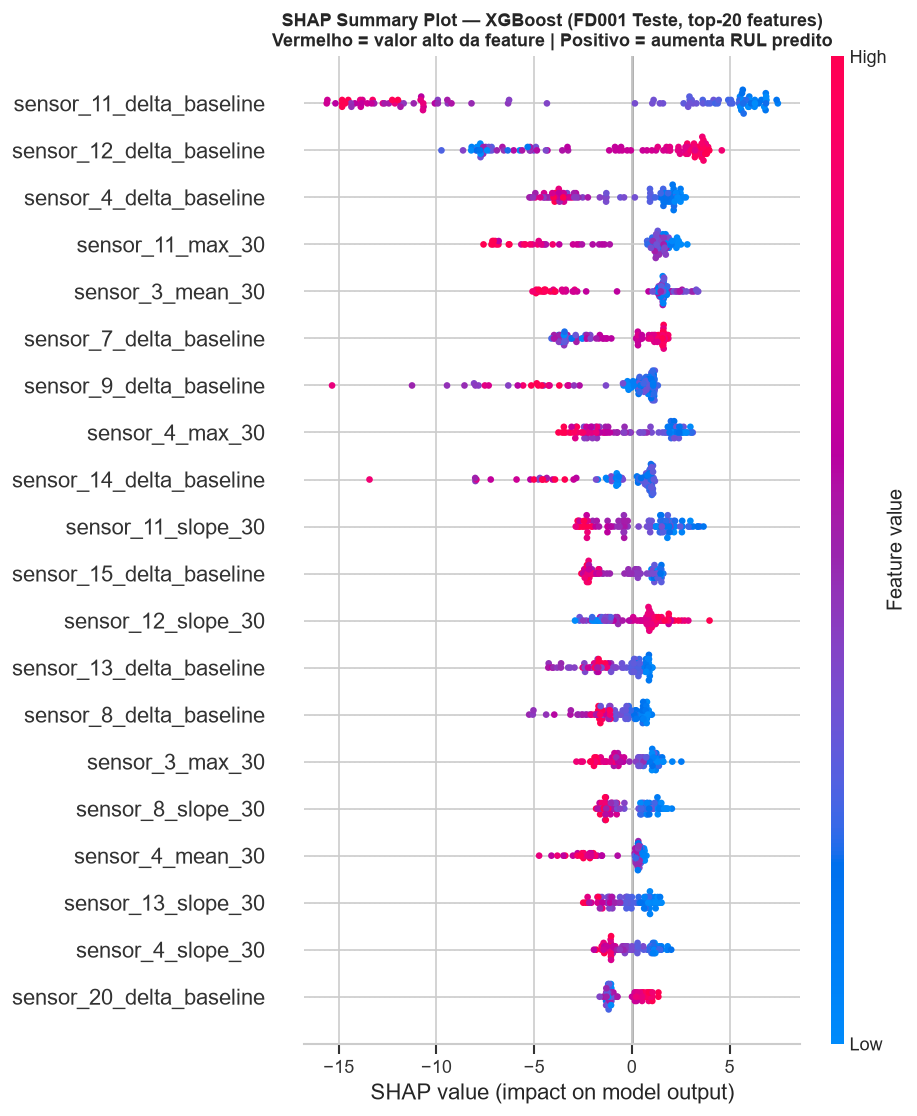

In [32]:
# Summary plot (beeswarm): cada ponto = 1 motor
# Cor = valor da feature (vermelho = alto, azul = baixo)
# Eixo X = impacto na previsao do RUL (ciclos)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_df, max_display=20, plot_type="dot", show=False)
plt.title(
    "SHAP Summary Plot — XGBoost (FD001 Teste, top-20 features)\n"
    "Vermelho = valor alto da feature | Positivo = aumenta RUL predito",
    fontsize=11, fontweight="bold"
)
plt.tight_layout()
plt.show()

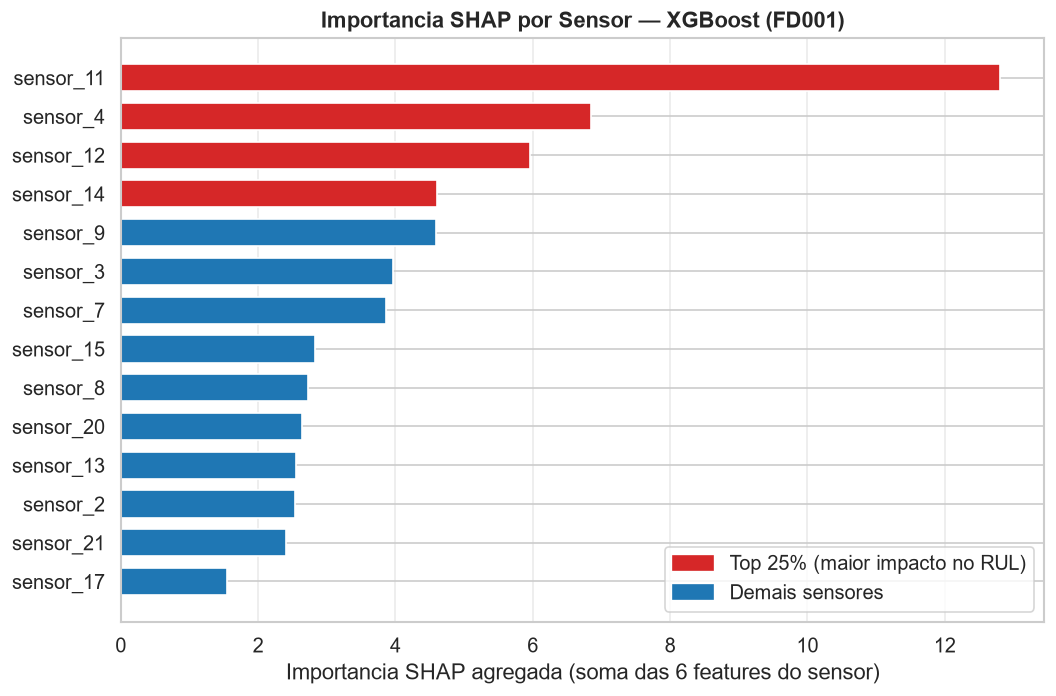

Ranking completo dos sensores por importancia SHAP:
sensor
sensor_11    12.8107
sensor_4      6.8460
sensor_12     5.9611
sensor_14     4.6093
sensor_9      4.5862
sensor_3      3.9572
sensor_7      3.8657
sensor_15     2.8254
sensor_8      2.7262
sensor_20     2.6402
sensor_13     2.5501
sensor_2      2.5409
sensor_21     2.4106
sensor_17     1.5460

Interpretacao para o artigo:
  sensor_11: importancia 12.811 — monitore este sensor com maior frequencia em operacao
  sensor_4: importancia 6.846 — monitore este sensor com maior frequencia em operacao
  sensor_12: importancia 5.961 — monitore este sensor com maior frequencia em operacao


In [33]:
top_75 = importancia_sensor.quantile(0.75)
cores_barra = ["#d62728" if v >= top_75 else "#1f77b4"
               for v in importancia_sensor.sort_values(ascending=True).values]

fig, ax = plt.subplots(figsize=(9, 6))
imp_sorted = importancia_sensor.sort_values(ascending=True)
ax.barh(imp_sorted.index, imp_sorted.values, color=cores_barra, edgecolor="white", height=0.7)
ax.set_xlabel("Importancia SHAP agregada (soma das 6 features do sensor)")
ax.set_title("Importancia SHAP por Sensor — XGBoost (FD001)", fontweight="bold")
legenda = [
    mpatches.Patch(color="#d62728", label="Top 25% (maior impacto no RUL)"),
    mpatches.Patch(color="#1f77b4", label="Demais sensores"),
]
ax.legend(handles=legenda, loc="lower right")
ax.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

print("Ranking completo dos sensores por importancia SHAP:")
print(importancia_sensor.round(4).to_string())
print("\nInterpretacao para o artigo:")
for s in top3_sensores:
    print(f"  {s}: importancia {importancia_sensor[s]:.3f} — "
          f"monitore este sensor com maior frequencia em operacao")

---
## 8. SHAP Waterfall — Da Previsão à Decisão de Manutenção

O waterfall plot decompõe a previsão de **um único motor** em contribuições individuais:
- A barra começa no **valor esperado** (E[f(x)] = previsão média do modelo)
- Cada feature **empurra** a previsão para cima (mais RUL) ou para baixo (menos RUL)
- O resultado final é a **previsão do modelo** para aquele motor

Analisamos dois motores extremos e, para cada um, extraímos a **recomendação de manutenção** — o objetivo final do sistema.

In [34]:
idx_critico  = int(np.argmin(y_pred_xgb))
idx_saudavel = int(np.argmax(y_pred_xgb))

for nome_caso, idx in [("CRITICO", idx_critico), ("SAUDAVEL", idx_saudavel)]:
    uid     = int(test_df.iloc[idx]["unit_id"])
    pred    = y_pred_xgb[idx]
    real    = y_test[idx]
    erro    = pred - real
    horas_pred = pred * HORAS_POR_CICLO

    print(f"Motor {nome_caso} (unit_id={uid}):")
    print(f"  RUL predito = {pred:.1f} ciclos = {horas_pred:.0f}h de voo restantes")
    print(f"  RUL real    = {real:.1f} ciclos")
    print(f"  Erro (d)    = {erro:+.1f} ciclos  "
          f"({'Atrasado — risco!' if erro > 0 else 'Adiantado — conservador'})")
    print()

Motor CRITICO (unit_id=81):
  RUL predito = 8.0 ciclos = 80h de voo restantes
  RUL real    = 8.0 ciclos
  Erro (d)    = +0.0 ciclos  (Atrasado — risco!)

Motor SAUDAVEL (unit_id=83):
  RUL predito = 125.7 ciclos = 1257h de voo restantes
  RUL real    = 137.0 ciclos
  Erro (d)    = -11.3 ciclos  (Adiantado — conservador)



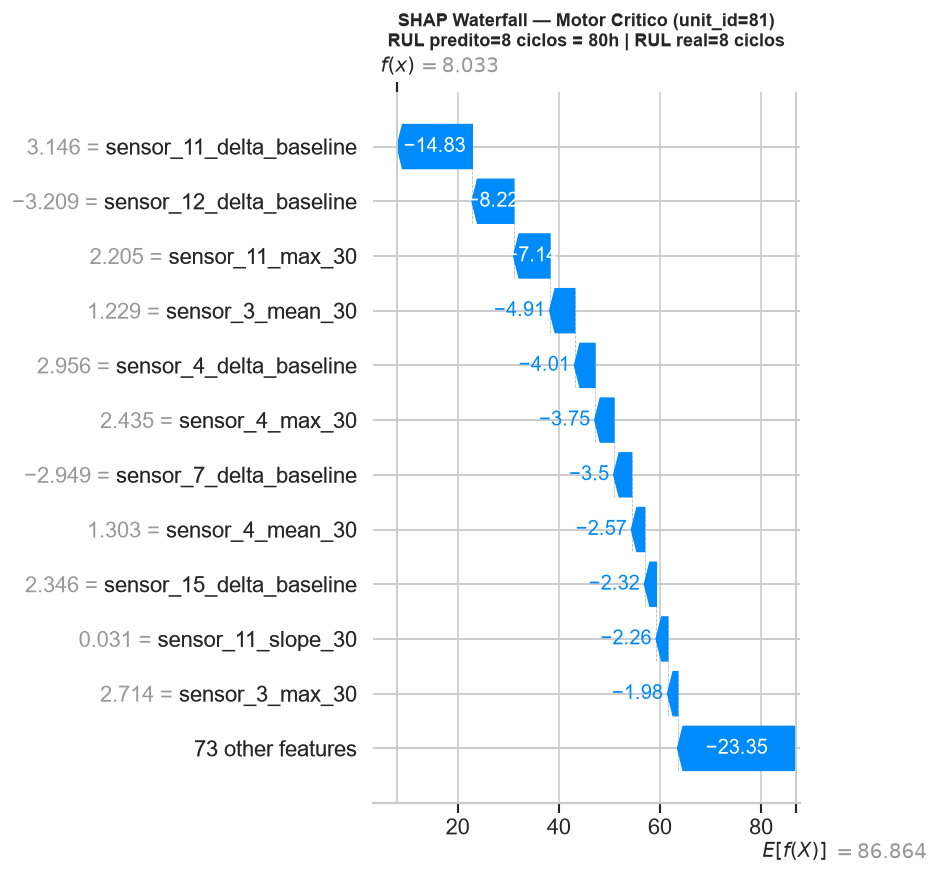

RECOMENDACAO DE MANUTENCAO — Motor Critico:
  RUL predito: 8 ciclos = 80 horas de voo
  Com margem de seguranca de 20% (padrao operacional):
  Agendar manutencao em ate 6 ciclos = 64h
  Features que mais aceleraram a degradacao (SHAP negativo): ver barras azuis no waterfall acima


In [35]:
idx = idx_critico
uid = int(test_df.iloc[idx]["unit_id"])
pred = y_pred_xgb[idx]

shap_exp_critico = shap.Explanation(
    values=shap_values[idx],
    base_values=float(explainer.expected_value),
    data=X_test_df.iloc[idx].values,
    feature_names=FEATURE_COLS,
)

plt.figure(figsize=(12, 6))
shap.plots.waterfall(shap_exp_critico, max_display=12, show=False)
plt.title(
    f"SHAP Waterfall — Motor Critico (unit_id={uid})\n"
    f"RUL predito={pred:.0f} ciclos = {pred*HORAS_POR_CICLO:.0f}h | RUL real={y_test[idx]:.0f} ciclos",
    fontsize=11, fontweight="bold"
)
plt.tight_layout()
plt.show()

# Decisão de manutenção
print("RECOMENDACAO DE MANUTENCAO — Motor Critico:")
print(f"  RUL predito: {pred:.0f} ciclos = {pred * HORAS_POR_CICLO:.0f} horas de voo")
print(f"  Com margem de seguranca de 20% (padrao operacional):")
janela_segura = pred * 0.8
print(f"  Agendar manutencao em ate {janela_segura:.0f} ciclos = {janela_segura * HORAS_POR_CICLO:.0f}h")
print(f"  Features que mais aceleraram a degradacao (SHAP negativo): "
      f"ver barras azuis no waterfall acima")

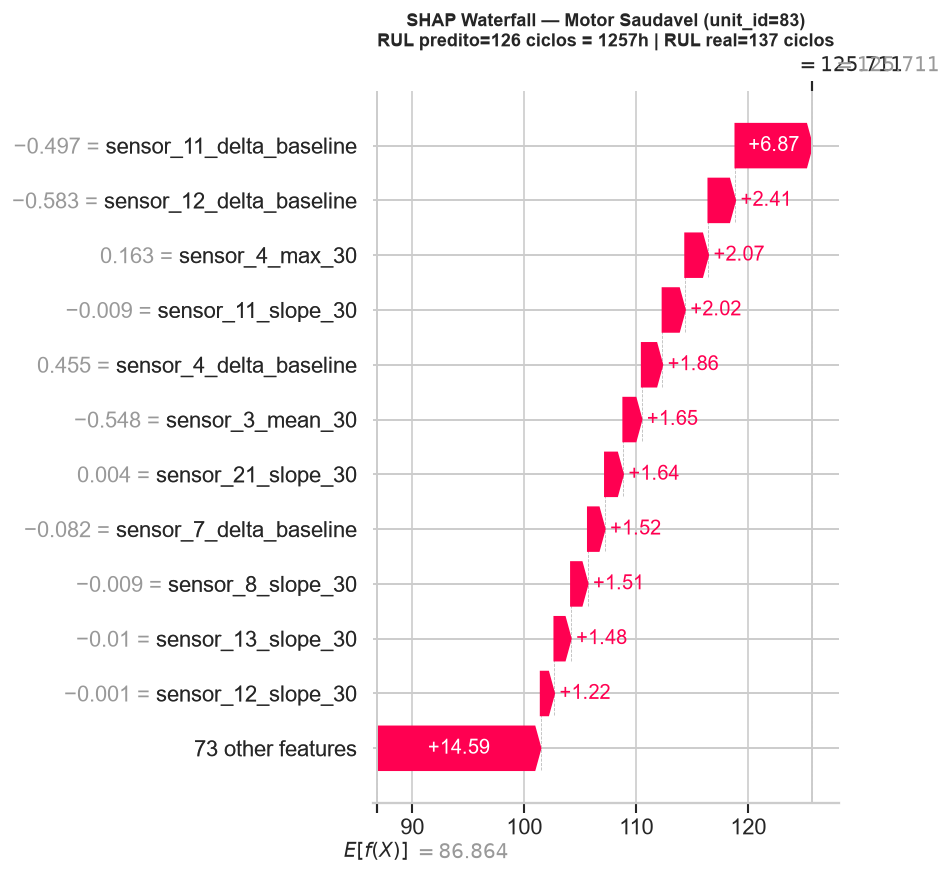

RECOMENDACAO DE MANUTENCAO — Motor Saudavel:
  RUL predito: 126 ciclos = 1257 horas de voo
  Motor pode continuar operando. Proxima verificacao em: 63 ciclos
  Monitorar a evolucao dos sensores identificados no waterfall acima.


In [36]:
idx = idx_saudavel
uid = int(test_df.iloc[idx]["unit_id"])
pred = y_pred_xgb[idx]

shap_exp_saudavel = shap.Explanation(
    values=shap_values[idx],
    base_values=float(explainer.expected_value),
    data=X_test_df.iloc[idx].values,
    feature_names=FEATURE_COLS,
)

plt.figure(figsize=(12, 6))
shap.plots.waterfall(shap_exp_saudavel, max_display=12, show=False)
plt.title(
    f"SHAP Waterfall — Motor Saudavel (unit_id={uid})\n"
    f"RUL predito={pred:.0f} ciclos = {pred*HORAS_POR_CICLO:.0f}h | RUL real={y_test[idx]:.0f} ciclos",
    fontsize=11, fontweight="bold"
)
plt.tight_layout()
plt.show()

print("RECOMENDACAO DE MANUTENCAO — Motor Saudavel:")
print(f"  RUL predito: {pred:.0f} ciclos = {pred * HORAS_POR_CICLO:.0f} horas de voo")
print(f"  Motor pode continuar operando. Proxima verificacao em: {pred * 0.5:.0f} ciclos")
print(f"  Monitorar a evolucao dos sensores identificados no waterfall acima.")

---
## 9. SHAP Dependence Plots — Como os Sensores Afetam a Previsão

O dependence plot mostra a relação entre o **valor de uma feature** e seu **impacto SHAP** na previsão do RUL. Uma linha decrescente indica que valores maiores da feature reduzem o RUL predito — comportamento esperado de um indicador de degradação. A cor codifica uma interação automática identificada pelo SHAP.

Top 3 features individuais: ['sensor_11_delta_baseline', 'sensor_12_delta_baseline', 'sensor_4_delta_baseline']


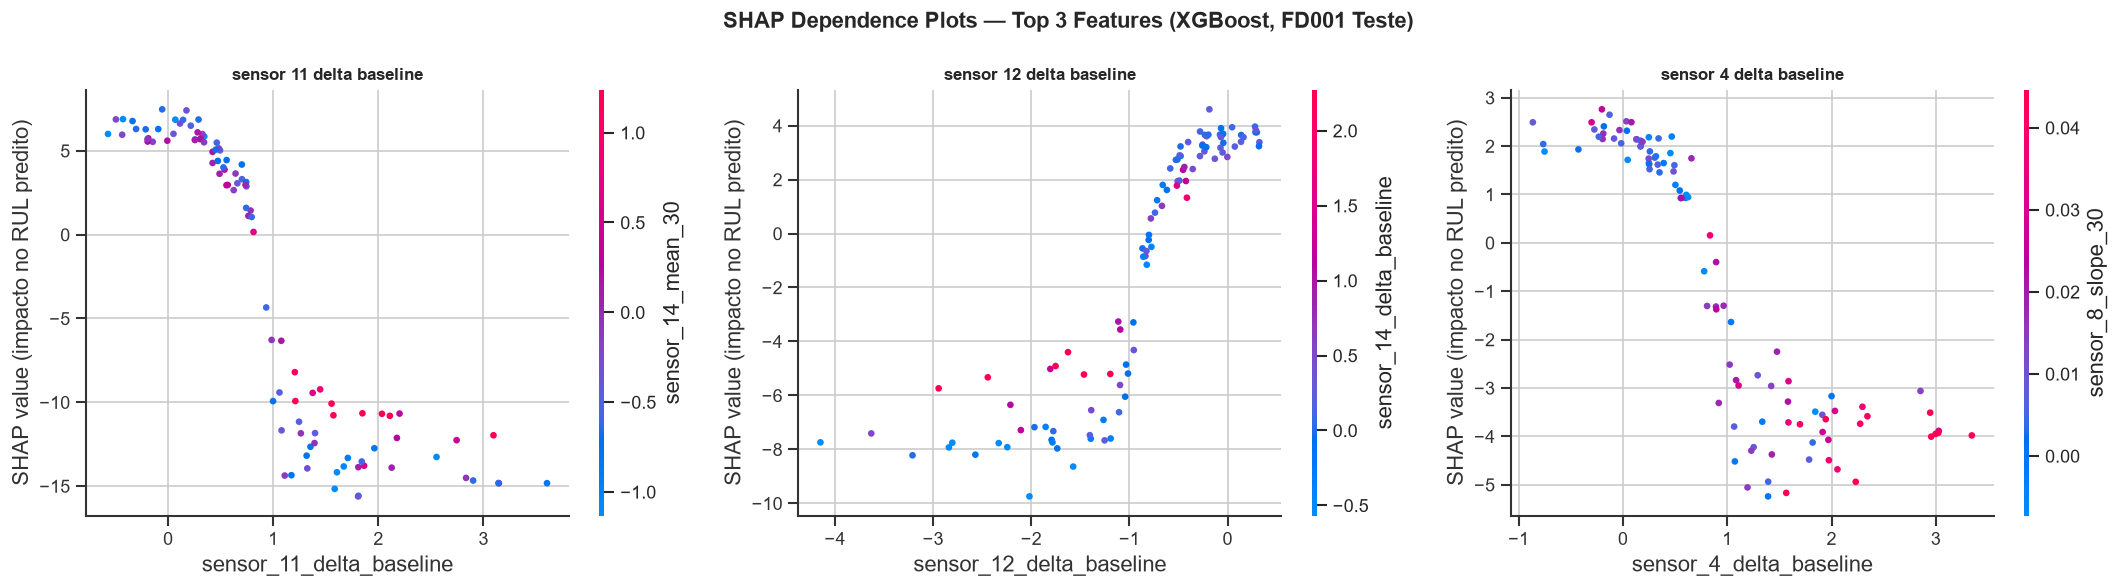

In [37]:
top3_features = (
    df_shap_feat
    .sort_values("mean_abs_shap", ascending=False)
    .head(3)["feature"]
    .tolist()
)
print(f"Top 3 features individuais: {top3_features}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, top3_features):
    shap.dependence_plot(feat, shap_values, X_test_df, ax=ax, show=False)
    ax.set_title(feat.replace("_", " "), fontsize=10, fontweight="bold")
    ax.set_ylabel("SHAP value (impacto no RUL predito)")

fig.suptitle("SHAP Dependence Plots — Top 3 Features (XGBoost, FD001 Teste)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 10. Limitações do Estudo

Todo trabalho científico — inclusive um MBA — precisa ser honesto sobre o que **não** pode ser concluído a partir dos resultados. As limitações abaixo não invalidam o trabalho, mas definem o escopo correto de aplicação.

### 10.1. Dados simulados, não operacionais

O C-MAPSS é gerado por um **simulador** (Commercial Modular Aero-Propulsion System Simulation), não por dados coletados de motores reais em operação. A performance do modelo pode ser diferente — tipicamente pior — em dados reais, que contêm:
- Ruído de sensor não-gaussiano
- Leituras faltantes e falhas de instrumentação
- Variabilidade de fabricação não capturada pelo simulador

**Implicação para o artigo:** os resultados estabelecem uma prova de conceito metodológica, não uma garantia de performance em produção.

### 10.2. Escopo limitado ao FD001

O FD001 é o cenário mais simples do C-MAPSS: uma condição operacional, um modo de falha. Os subsets FD002 e FD004 (múltiplos regimes operacionais) apresentam desafios adicionais que não foram modelados neste trabalho — normalização por regime operacional seria necessária.

### 10.3. Previsão pontual sem intervalo de confiança

O modelo retorna um único valor de RUL por motor — sem intervalo de confiança. Em operação real, um gestor de manutenção precisa saber não apenas *"o modelo prevê 47 ciclos"*, mas também *"com 90% de confiança, o motor tem entre 35 e 59 ciclos"*. Técnicas como **Conformal Prediction** ou **Quantile Regression** poderiam adicionar essa camada.

### 10.4. Ausência de tratamento de concept drift

O modelo assume que o padrão de degradação aprendido no treino permanece válido no futuro. Em operação real, mudanças de manutenção, atualização de componentes ou novos perfis de missão podem alterar o comportamento dos sensores — o modelo precisaria de retreinamento periódico.

### 10.5. Avaliação no último ciclo observado

O conjunto de teste do C-MAPSS fornece o histórico de cada motor até um ponto de corte, e a previsão é feita **uma única vez** no último ciclo. Em produção, o modelo seria chamado a cada ciclo, acumulando erro ao longo do tempo — uma avaliação mais realista usaria previsões contínuas e mediria a estabilidade temporal do RUL predito.

---
## 11. Síntese para o Artigo

Esta seção consolida todos os resultados em formato diretamente utilizável para as seções de Resultados e Conclusão do artigo de MBA.

In [38]:
xgb_row   = df_resultados[df_resultados.modelo == "XGBoost"].iloc[0]
ridge_row  = df_resultados[df_resultados.modelo == "Ridge"].iloc[0]
stk_row    = df_resultados[df_resultados.modelo == "Stacking"].iloc[0]

ganho_rmse = ridge_row["test_rmse"] - xgb_row["test_rmse"]
ganho_phm  = ridge_row["test_phm"]  - xgb_row["test_phm"]
aprovados  = df_resultados[df_resultados.test_rmse < 15.0]["modelo"].tolist()

print("=" * 70)
print("SINTESE FINAL — FD001 (100 motores de teste | benchmark < 15 ciclos)")
print("=" * 70)

print("\n1. PERFORMANCE DOS MODELOS")
print(f"   {'Modelo':<16s} {'RMSE':>7s} {'MAE':>7s} {'PHM':>8s} {'Aprovado?':>10s}")
print("   " + "-" * 52)
for _, row in df_resultados.iterrows():
    aprov = "SIM" if row["test_rmse"] < 15.0 else "NAO"
    marca = " <-- recomendado" if row["modelo"] == "XGBoost" else ""
    print(f"   {row['modelo']:<16s} {row['test_rmse']:>7.2f} {row['test_mae']:>7.2f} "
          f"{row['test_phm']:>8.0f} {aprov:>10s}{marca}")

print(f"\n2. GANHO SOBRE O BASELINE (Ridge)")
print(f"   RMSE: -{ganho_rmse:.2f} ciclos = -{ganho_rmse * HORAS_POR_CICLO:.0f}h de incerteza "
      f"({ganho_rmse / ridge_row['test_rmse'] * 100:.0f}% de reducao)")
print(f"   PHM Score: -{ganho_phm:.0f} pontos")

print(f"\n3. INTERPRETABILIDADE — TOP 3 SENSORES (SHAP XGBoost)")
for i, s in enumerate(top3_sensores, 1):
    print(f"   {i}. {s}  (importancia agregada: {importancia_sensor[s]:.3f})")

print(f"\n4. SEGURANCA OPERACIONAL")
print(f"   XGBoost: {(y_pred_xgb < y_test).mean()*100:.0f}% das previsoes sao adiantadas (conservadoras)")
print(f"   PHM Score {xgb_row['test_phm']:.0f} vs Ridge {ridge_row['test_phm']:.0f}: "
      f"reducao de risco operacional em {ganho_phm / ridge_row['test_phm'] * 100:.0f}%")

print(f"\n5. RECOMENDACAO FINAL")
print(f"   Modelo: XGBoost")
print(f"   Justificativa: melhor RMSE/MAE/PHM no teste, suporte a SHAP nativo,")
print(f"   tamanho 81x menor que Stacking (840KB vs 81MB), com ganho de apenas")
print(f"   {abs(stk_row['test_rmse'] - xgb_row['test_rmse']):.3f} ciclos de RMSE a favor do Stacking.")

print(f"\n6. LIMITACOES PRINCIPAIS")
print(f"   - Dados simulados (C-MAPSS), nao operacionais reais")
print(f"   - Escopo: FD001 (1 regime, 1 modo de falha)")
print(f"   - Previsao pontual sem intervalo de confianca")
print(f"   - Sem tratamento de concept drift")

SINTESE FINAL — FD001 (100 motores de teste | benchmark < 15 ciclos)

1. PERFORMANCE DOS MODELOS
   Modelo              RMSE     MAE      PHM  Aprovado?
   ----------------------------------------------------
   Ridge              18.59   14.85      501        NAO
   Random Forest      13.42   10.02      253        SIM
   XGBoost            12.50    9.04      206        SIM <-- recomendado
   LightGBM           12.79    9.27      222        SIM
   Stacking           12.74    9.18      220        SIM

2. GANHO SOBRE O BASELINE (Ridge)
   RMSE: -6.10 ciclos = -61h de incerteza (33% de reducao)
   PHM Score: -295 pontos

3. INTERPRETABILIDADE — TOP 3 SENSORES (SHAP XGBoost)
   1. sensor_11  (importancia agregada: 12.811)
   2. sensor_4  (importancia agregada: 6.846)
   3. sensor_12  (importancia agregada: 5.961)

4. SEGURANCA OPERACIONAL
   XGBoost: 37% das previsoes sao adiantadas (conservadoras)
   PHM Score 206 vs Ridge 501: reducao de risco operacional em 59%

5. RECOMENDACAO FINAL
  